# Fase 2. Hipótesis y pruebas estadísticas

Juan Pablo Vasquez Tobon

Las preguntas de la Fase 1 se pasan a hipótesis y se prueban con los datos limpios de la Fase 3. Se usa α = 0,05.

| Pregunta | Hipótesis | Variables |
|---|---|---|
| Qué géneros venden más por título? | H1 | Genero, Global_Sales |
| Las preferencias de género cambian según la región? | H2, H2b | Genero, Region_Dominante, Share_JP |
| Los first-party venden más que los de terceros? | H3 | First_Party, Fabricante, Global_Sales |

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scikit_posthocs as sp
from scipy import stats
import estilo

estilo.configurar()
df = pd.read_csv(estilo.LIMPIO)
ALFA = 0.05
resultados = []
print(len(df), "registros")

16322 registros


1. Normalidad

Primero se revisa si las ventas son normales para saber que prueba usar.

Media: 0.54 M | Mediana: 0.17 M
Asimetría: 17.3 | Curtosis: 597
Shapiro-Wilk: W = 0.237, p = 1.5e-89


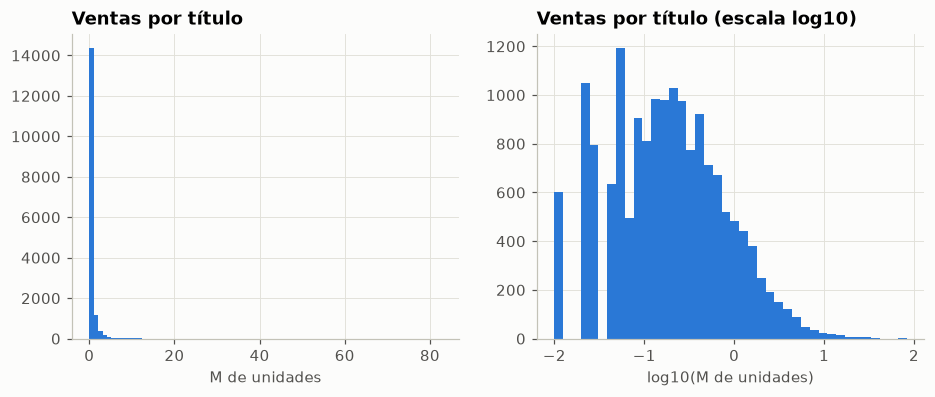

In [2]:
v = df["Global_Sales"]
print(f"Media: {v.mean():.2f} M | Mediana: {v.median():.2f} M")
print(f"Asimetría: {stats.skew(v):.1f} | Curtosis: {stats.kurtosis(v):.0f}")

# shapiro con una muestra de 5000
muestra = v.sample(5000, random_state=8)
w, p = stats.shapiro(muestra)
print(f"Shapiro-Wilk: W = {w:.3f}, p = {p:.1e}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(v, bins=80, color=estilo.AZUL)
axes[0].set_title("Ventas por título")
axes[0].set_xlabel("M de unidades")
axes[1].hist(np.log10(v[v > 0]), bins=40, color=estilo.AZUL)
axes[1].set_title("Ventas por título (escala log10)")
axes[1].set_xlabel("log10(M de unidades)")
estilo.guardar(fig, "f2_normalidad")
plt.show()

Las ventas no son normales, la mayoria de juegos vende poco y unos pocos venden mucho. Por eso se usan pruebas no paramétricas: Kruskal-Wallis con Dunn, chi-cuadrado y Mann-Whitney U.

Como hay mas de 16.000 registros casi todo sale significativo, entonces tambien se calcula el tamaño del efecto.

2. H1. Ventas por título según el género

- H0: las ventas por título son iguales en todos los géneros.
- H1: al menos un género vende distinto.

Importa porque el género es de las primeras decisiones al hacer un juego.

Prueba: Kruskal-Wallis. Efecto: ε² = H / (n - 1).

In [3]:
orden = df.groupby("Genero")["Global_Sales"].median().sort_values(ascending=False).index
grupos = [df.loc[df["Genero"] == g, "Global_Sales"] for g in orden]

H, p = stats.kruskal(*grupos)
n = len(df)
eps2 = H / (n - 1)
print(f"H = {H:.1f}, gl = {len(grupos) - 1}, p = {p:.1e}, ε² = {eps2:.3f}")
print("Se rechaza H0" if p < ALFA else "No se rechaza H0")
resultados.append(["H1. Ventas por título según el género", "Kruskal-Wallis", p, f"ε² = {eps2:.3f}"])

df.groupby("Genero")["Global_Sales"].agg(titulos="size", mediana="median", media="mean").loc[orden].round(2)

H = 974.4, gl = 11, p = 6.1e-202, ε² = 0.060
Se rechaza H0


,titulos,mediana,media
Genero,,,
Plataformas,876,0.28,0.95
Disparos,1282,0.23,0.80
Deportes,2303,0.22,0.57
Pelea,836,0.21,0.53
Acción,3252,0.19,0.53
Carreras,1226,0.19,0.59
Rol (RPG),1469,0.19,0.63
Simulación,850,0.16,0.46
Misceláneo,1710,0.16,0.47


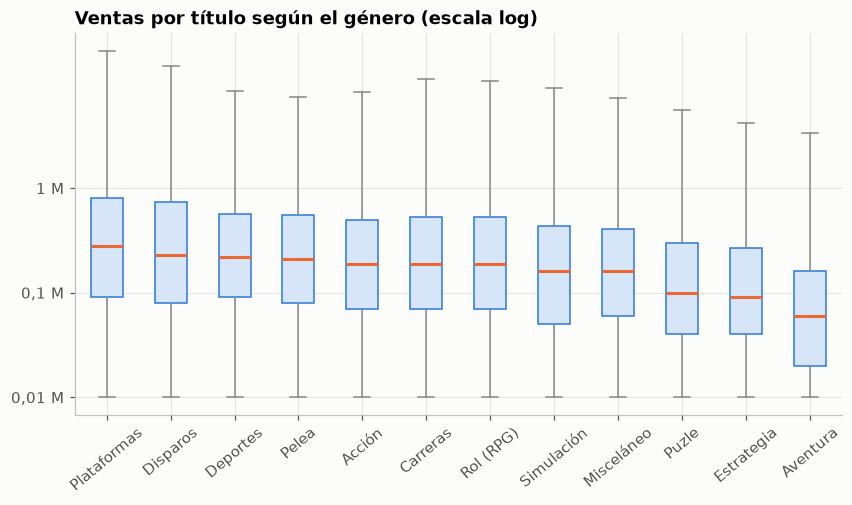

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.boxplot([np.log10(g[g > 0]) for g in grupos], tick_labels=orden, showfliers=False,
           patch_artist=True, boxprops=dict(facecolor="#d6e6f8", color=estilo.AZUL),
           medianprops=dict(color=estilo.NARANJA, lw=2), whiskerprops=dict(color=estilo.GRIS),
           capprops=dict(color=estilo.GRIS))
ax.set_yticks([-2, -1, 0], ["0,01 M", "0,1 M", "1 M"])
ax.tick_params(axis="x", rotation=40)
ax.set_title("Ventas por título según el género (escala log)")
estilo.guardar(fig, "f2_h1_genero")
plt.show()

Post hoc de Dunn con corrección de Bonferroni para ver que pares de géneros son diferentes.

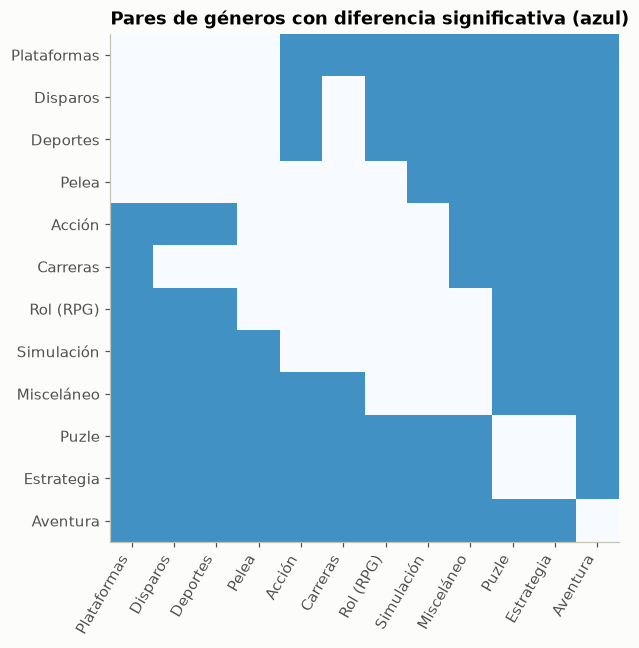

46 de 66 pares son significativos
Aventura difiere de: Plataformas, Disparos, Deportes, Pelea, Acción, Carreras, Rol (RPG), Simulación, Misceláneo, Puzle, Estrategia


In [5]:
dunn = sp.posthoc_dunn(df, val_col="Global_Sales", group_col="Genero", p_adjust="bonferroni")
dunn = dunn.loc[orden, orden]

fig, ax = plt.subplots(figsize=(7, 6))
sig = (dunn < ALFA).astype(int).values
ax.imshow(sig, cmap="Blues", vmin=0, vmax=1.6)
ax.set_xticks(range(len(orden)), orden, rotation=60, ha="right")
ax.set_yticks(range(len(orden)), orden)
ax.grid(False)
ax.set_title("Pares de géneros con diferencia significativa (azul)")
estilo.guardar(fig, "f2_h1_dunn")
plt.show()

pares = [(a, b) for i, a in enumerate(orden) for b in orden[i + 1:]]
n_sig = sum(dunn.loc[a, b] < ALFA for a, b in pares)
print(f"{n_sig} de {len(pares)} pares son significativos")
print("Aventura difiere de:", ", ".join(g for g in orden if g != "Aventura" and dunn.loc["Aventura", g] < ALFA))

Se rechaza H0. Plataformas y Disparos tienen las medianas mas altas y Aventura la mas baja. Sin embargo el ε² es pequeño (0,06), el género influye pero explica poco de las ventas.

3. H2. Región dominante según el género

- H0: el género y la región dominante son independientes.
- H1: la región donde mas vende un juego depende de su género.

Importa para saber a que mercado apuntar segun el género.

Prueba: chi-cuadrado de independencia, sin los 337 registros con empate. Efecto: V de Cramér.

In [6]:
d2 = df[df["Region_Dominante"] != "Empate"]
tabla = pd.crosstab(d2["Genero"], d2["Region_Dominante"])[["Norteamérica", "Europa", "Japón"]]

chi2, p, gl, esperados = stats.chi2_contingency(tabla)
v_cramer = np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))
print(f"χ² = {chi2:.1f}, gl = {gl}, p = {p:.1e}, V de Cramér = {v_cramer:.3f}")
print("Celdas con frecuencia esperada < 5:", (esperados < 5).sum())
print("Se rechaza H0" if p < ALFA else "No se rechaza H0")
resultados.append(["H2. Región dominante según el género", "Chi-cuadrado", p, f"V = {v_cramer:.3f}"])

tabla

χ² = 2098.3, gl = 22, p = 0.0e+00, V de Cramér = 0.256
Celdas con frecuencia esperada < 5: 0
Se rechaza H0


Region_Dominante,Norteamérica,Europa,Japón
Genero,,,
Acción,1996,509,661
Aventura,429,156,669
Carreras,884,245,66
Deportes,1536,339,393
Disparos,902,242,104
Estrategia,243,187,228
Misceláneo,1061,190,438
Pelea,483,43,294
Plataformas,686,78,93


El valor p sale 0 porque es menor a 1e-300. Abajo los residuos estandarizados, los mayores a 2 o menores a -2 son los que pesan.

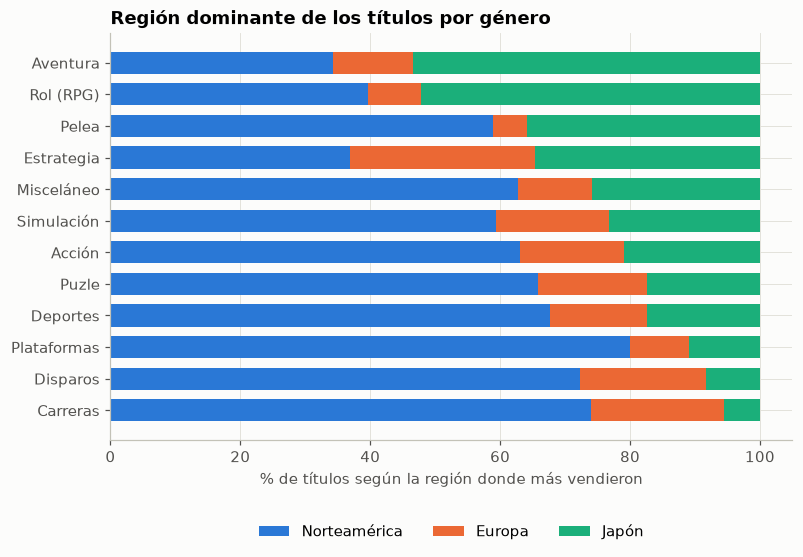

Region_Dominante,Norteamérica,Europa,Japón
Genero,,,
Aventura,-11.9,-2.1,20.1
Rol (RPG),-10.1,-6.5,20.7
Pelea,-0.5,-7.0,6.3
Estrategia,-7.7,9.2,5.0
Misceláneo,1.3,-3.7,0.8
Simulación,-0.4,2.1,-1.0
Acción,1.9,2.1,-4.6
Puzle,1.7,1.3,-3.6
Deportes,4.5,0.4,-7.3


In [7]:
residuos = (tabla - esperados) / np.sqrt(esperados)
mezcla = tabla.div(tabla.sum(axis=1), axis=0).sort_values("Japón")

fig, ax = plt.subplots(figsize=(8, 4.8))
izq = np.zeros(len(mezcla))
for region in mezcla.columns:
    ax.barh(mezcla.index, mezcla[region] * 100, left=izq, color=estilo.COLOR_REGION[region],
            label=region, height=0.7)
    izq += mezcla[region].values * 100
ax.set_xlabel("% de títulos según la región donde más vendieron")
ax.set_title("Región dominante de los títulos por género")
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.28))
estilo.guardar(fig, "f2_h2_region_genero")
plt.show()

residuos.loc[mezcla.index[::-1]].round(1)

Se rechaza H0. La V de Cramér es 0,26, mas alta que el efecto de H1. Rol y Aventura venden mas en Japón de lo esperado y Carreras, Disparos y Plataformas mucho menos.

H2b. Japón en los juegos de Rol

- H0: la participación de Japón en los juegos de Rol es igual o menor que en el resto.
- H1: la participación de Japón es mayor en Rol.

Prueba: Mann-Whitney U de una cola sobre Share_JP. Efecto: r = 2U / (n1·n2) - 1.

In [8]:
s = df.dropna(subset=["Share_JP"])
rol = s.loc[s["Genero"] == "Rol (RPG)", "Share_JP"]
otros = s.loc[s["Genero"] != "Rol (RPG)", "Share_JP"]

U, p = stats.mannwhitneyu(rol, otros, alternative="greater")
r = 2 * U / (len(rol) * len(otros)) - 1
print(f"Rol: n = {len(rol)}, mediana Share_JP = {rol.median():.1%}")
print(f"Otros: n = {len(otros)}, mediana Share_JP = {otros.median():.1%}")
print(f"U = {U:.0f}, p = {p:.1e}, r = {r:.3f}")
print("Se rechaza H0" if p < ALFA else "No se rechaza H0")
resultados.append(["H2b. Japón pesa más en los juegos de Rol", "Mann-Whitney U", p, f"r = {r:.3f}"])

Rol: n = 1469, mediana Share_JP = 40.9%
Otros: n = 14852, mediana Share_JP = 0.0%
U = 15059888, p = 1.6e-171, r = 0.381
Se rechaza H0


Se rechaza H0. Un juego de Rol hace en la mediana el 41 % de sus ventas en Japón, los demás 0 %.

4. H3. First-party vs terceros

- H0: los first-party venden igual o menos que los terceros.
- H1: los first-party venden más.

Importa porque un publisher mediano siempre es tercero.

Prueba: Mann-Whitney U de una cola, solo en consolas de Nintendo, Sony, Microsoft y Sega.

In [9]:
d3 = df[df["Fabricante"].isin(["Nintendo", "Sony", "Microsoft", "Sega"])]
fp = d3.loc[d3["First_Party"], "Global_Sales"]
tp = d3.loc[~d3["First_Party"], "Global_Sales"]

U, p = stats.mannwhitneyu(fp, tp, alternative="greater")
r = 2 * U / (len(fp) * len(tp)) - 1
print(f"First-party: n = {len(fp)}, mediana = {fp.median():.2f} M")
print(f"Terceros:    n = {len(tp)}, mediana = {tp.median():.2f} M")
print(f"U = {U:.0f}, p = {p:.1e}, r = {r:.3f}")
print("Se rechaza H0" if p < ALFA else "No se rechaza H0")
resultados.append(["H3. Los first-party venden más que los terceros", "Mann-Whitney U", p, f"r = {r:.3f}"])

First-party: n = 1687, mediana = 0.48 M
Terceros:    n = 13552, mediana = 0.16 M
U = 16072801, p = 8.5e-164, r = 0.406
Se rechaza H0


In [10]:
# misma prueba por fabricante
filas = []
for fab, g in d3.groupby("Fabricante"):
    a, b = g.loc[g["First_Party"], "Global_Sales"], g.loc[~g["First_Party"], "Global_Sales"]
    U, p = stats.mannwhitneyu(a, b, alternative="greater")
    filas.append([fab, len(a), len(b), a.median(), b.median(), a.median() / b.median(),
                  a.sum() / g["Global_Sales"].sum(), p, 2 * U / (len(a) * len(b)) - 1])
por_fab = pd.DataFrame(filas, columns=["Fabricante", "n first-party", "n terceros", "mediana FP",
                                       "mediana terceros", "veces", "% ventas FP", "p", "r"])
por_fab.set_index("Fabricante").round({"mediana FP": 2, "mediana terceros": 2, "veces": 1,
                                        "% ventas FP": 3, "r": 3})

,n first-party,n terceros,mediana FP,mediana terceros,veces,% ventas FP,p,r
Fabricante,,,,,,,,
Microsoft,159,2092,0.51,0.20,2.6,0.174,3.522021e-12,0.326
Nintendo,696,5472,0.92,0.14,6.6,0.511,5.181024e-163,0.631
Sega,132,127,0.14,0.11,1.2,0.660,4.053045e-03,0.190
Sony,700,5861,0.34,0.18,1.9,0.179,1.161311e-33,0.278


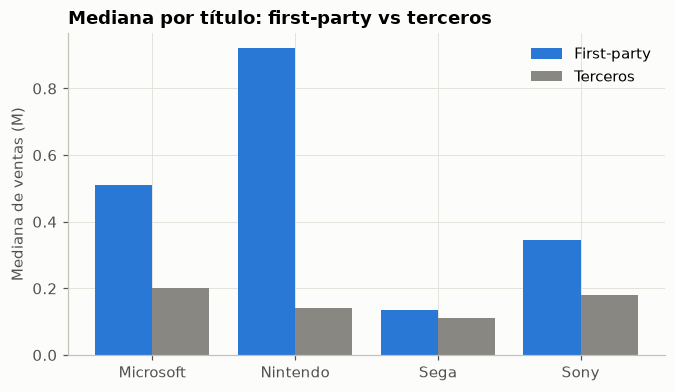

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.8))
x = np.arange(len(por_fab))
ax.bar(x - 0.2, por_fab["mediana FP"], 0.4, color=estilo.AZUL, label="First-party")
ax.bar(x + 0.2, por_fab["mediana terceros"], 0.4, color=estilo.GRIS, label="Terceros")
ax.set_xticks(x, por_fab["Fabricante"])
ax.set_ylabel("Mediana de ventas (M)")
ax.set_title("Mediana por título: first-party vs terceros")
ax.legend()
estilo.guardar(fig, "f2_h3_first_party")
plt.show()

Se rechaza H0. Los first-party venden 3 veces mas en la mediana, y en Nintendo 6,6 veces. En Sony y Microsoft los terceros tienen mas del 80 % de las ventas.

Esto es relación y no causa, puede ser por presupuesto o franquicias mas conocidas.

5. Resumen

In [12]:
resumen = pd.DataFrame(resultados, columns=["Hipótesis (H1)", "Prueba", "Valor p", "Efecto"])
resumen["Decisión"] = np.where(resumen["Valor p"] < ALFA, "Se rechaza H0", "No se rechaza H0")
resumen["Valor p"] = resumen["Valor p"].map(lambda p: "< 1e-300" if p == 0 else f"{p:.1e}")
resumen.to_csv(estilo.RAIZ / "data" / "processed" / "hipotesis.csv", index=False, encoding="utf-8")
resumen

,Hipótesis (H1),Prueba,Valor p,Efecto,Decisión
0,H1. Ventas por título según el género,Kruskal-Wallis,6.1e-202,ε² = 0.060,Se rechaza H0
1,H2. Región dominante según el género,Chi-cuadrado,< 1e-300,V = 0.256,Se rechaza H0
2,H2b. Japón pesa más en los juegos de Rol,Mann-Whitney U,1.6e-171,r = 0.381,Se rechaza H0
3,H3. Los first-party venden más que los terceros,Mann-Whitney U,8.5e-164,r = 0.406,Se rechaza H0


En las cuatro pruebas se rechaza H0. El género influye poco en cuanto vende un juego pero mucho en donde se vende, y los first-party tienen ventaja sobre todo en Nintendo. Estos resultados se usan en los KPIs de la Fase 4.